In [17]:
import torch
import os
import matplotlib.pyplot as plt
import numpy as np
from torchvision import datasets, transforms

from sklearn.metrics.pairwise import euclidean_distances

In [13]:
dir_data="/Users/nicolekan/Workspace/nus/data_valuation/data/"
dir_tensors = os.path.join("/Users/nicolekan/Workspace/nus/data_valuation/influences", "mnist")
dir_ckpt = "/Users/nicolekan/Workspace/nus/data_valuation/checkpoint/"

num_epochs = 10
ckpt_min = 3
ckpt_max = 10
ckpt_step = 3
p = 0.95
checkpoint_labels =  list(range(ckpt_min, ckpt_max, ckpt_step))

In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x.view(-1)) 
])
    
mnist_train = datasets.MNIST(dir_data, train=True, download=False, transform=transform)

In [20]:
train_losses = torch.load(f"{dir_tensors}/mnist_train_losses.pt", weights_only=False)
validation_losses = torch.load(f"{dir_tensors}/mnist_validation_losses.pt", weights_only=False)

accuracies = torch.load(f"{dir_tensors}/mnist_accuracies.pt", weights_only=False)

In [23]:
validation_losses

[1.570099115371704,
 1.5458825143279544,
 1.5366260557417657,
 1.5280936751396033,
 1.5215834067885283,
 1.5183279195408912,
 1.513998471247922,
 1.5117203042765333,
 1.508641982534129,
 1.5063637198915907]

In [5]:
epochs_range = range(1, num_epochs + 1)
train_losses = [loss.item() for loss in train_losses]

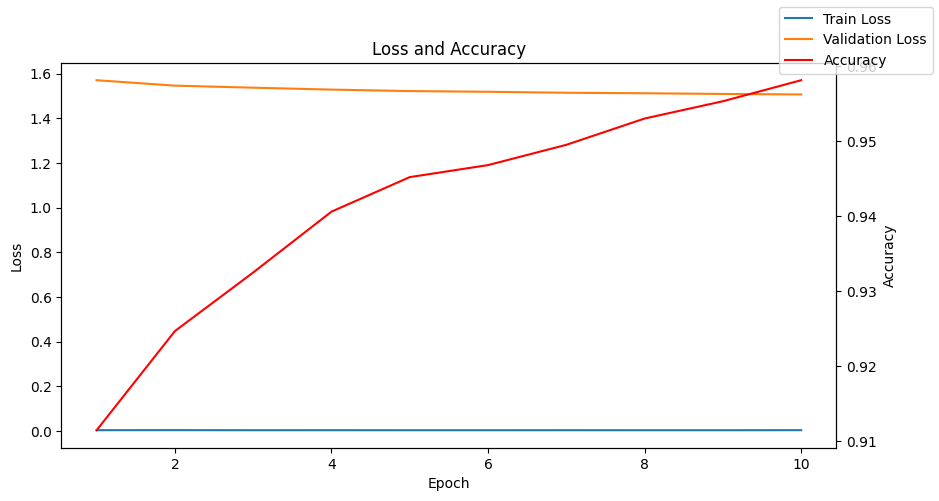

In [6]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(epochs_range, train_losses, label='Train Loss')
ax1.plot(epochs_range, validation_losses, label='Validation Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')

ax2 = ax1.twinx()
ax2.plot(epochs_range, accuracies, label='Accuracy', color='r')
ax2.set_ylabel('Accuracy')

plt.title('Loss and Accuracy')
fig.legend()
plt.show()

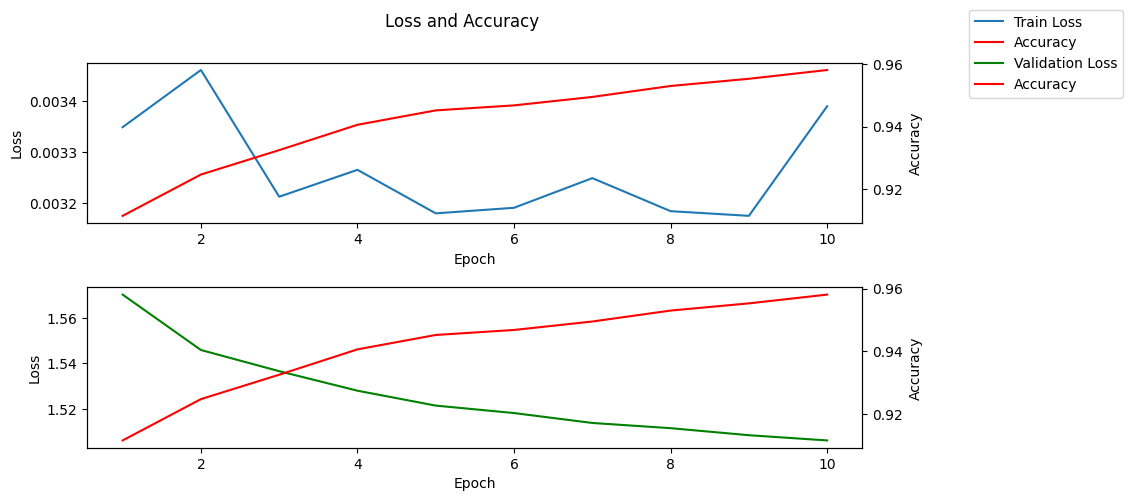

In [7]:
x_vals = np.arange(1, 11)
fig = plt.figure(figsize=(10, 5))
ax1 = fig.add_subplot(211)
ax1.plot(x_vals, train_losses, label='Train Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')

ax2 = ax1.twinx()
ax2.plot(x_vals, accuracies, label='Accuracy', color='r')
ax2.set_ylabel('Accuracy')

ax3 = fig.add_subplot(212)
ax3.plot(x_vals, validation_losses, label='Validation Loss', color='g')
ax4 = ax3.twinx()
ax3.set_xlabel('Epoch')
ax3.set_ylabel('Loss')
ax4.plot(x_vals, accuracies, label='Accuracy', color='r')
ax4.set_ylabel('Accuracy')

fig.suptitle('Loss and Accuracy')
fig.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.subplots_adjust(hspace=0.4)
plt.show()

# Influences

In [8]:
mnist_influences = torch.load(f"{dir_tensors}/mnist_influences.pt", weights_only=False)

In [9]:
def top_or_least_influences(ckpt_influences, train_dataset, num_per_row=10, descending=True):
    ckpt_num = len(ckpt_influences)
    # fig, ax = plt.subplots(ckpt_num, num_per_row, figsize=(20, 20))
    ckpt_imgs = []
    for ckpt, influences in enumerate(ckpt_influences):
        sorted_influences = torch.argsort(torch.from_numpy(influences), descending=descending)
        top_indexes = sorted_influences[:num_per_row]
        top_influential_train_data = [train_dataset[index] for index in top_indexes]
        ckpt_imgs.append(top_influential_train_data)
    return ckpt_imgs
    
mnist_ckpt_imgs = top_or_least_influences(mnist_influences, mnist_train, num_per_row=20)
num_data = len(mnist_train)
x_vals =  list(range(1, 11))

In [10]:
validate_validation_losses = torch.load(f"{dir_tensors}/mnist_validate_validation_losses.pt",  weights_only=False)
rand_validate_accuracies = torch.load(f"{dir_tensors}/mnist_rand_validate_accuracies.pt",  weights_only=False)
rand_validate_train_losses = torch.load(f"{dir_tensors}/mnist_rand_validate_train_losses.pt",  weights_only=False)
validate_accuracies = torch.load(f"{dir_tensors}/mnist_validate_accuracies.pt",  weights_only=False)

In [25]:
rand_validate_accuracies

[[0.9103000164031982, 0.9253000020980835, 0.9325000047683716],
 [0.9089000225067139,
  0.9233999848365784,
  0.9298999905586243,
  0.9386000037193298,
  0.9409000277519226,
  0.9466999769210815],
 [0.8921999931335449,
  0.9248999953269958,
  0.9319999814033508,
  0.9383999705314636,
  0.9422000050544739,
  0.945900022983551,
  0.9491000175476074,
  0.9526000022888184,
  0.9559000134468079]]

In [11]:
checkpoints_filepaths = [os.path.join(dir_ckpt, f"epoch_{epoch}_{epoch/num_epochs}.pth") for epoch in checkpoint_labels]
checkpoints_filepaths

['/Users/nicolekan/Workspace/nus/data_valuation/checkpoint/epoch_3_0.3.pth',
 '/Users/nicolekan/Workspace/nus/data_valuation/checkpoint/epoch_6_0.6.pth',
 '/Users/nicolekan/Workspace/nus/data_valuation/checkpoint/epoch_9_0.9.pth']

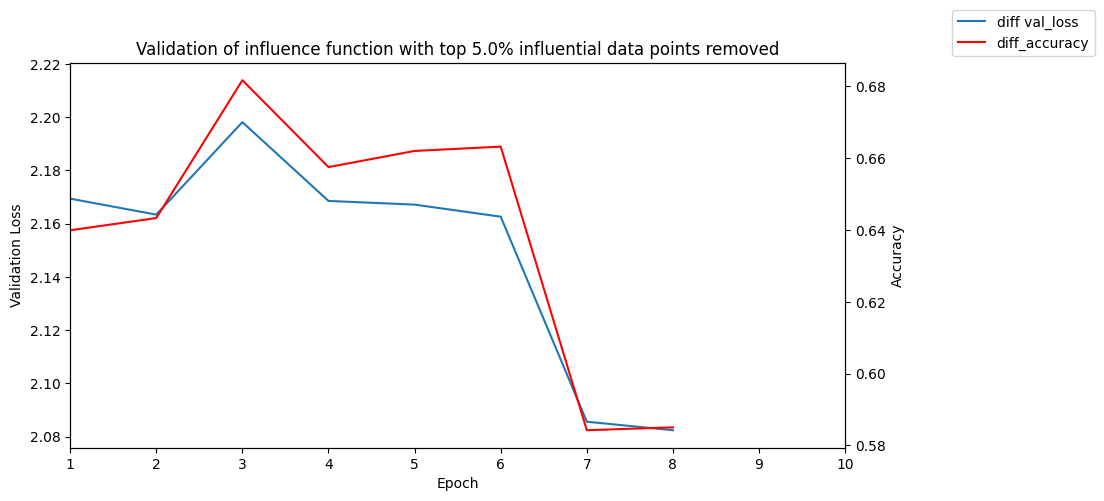

In [15]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))
def concat_ckpt_metrics(metrics, ckpt_labels):
    integrate_metrics = []
    for i, metric in enumerate(metrics):
        prev_ckpt = ckpt_labels[i-1] if i > 0 else 0
        integrate_metrics.append(metric[prev_ckpt:])
    return np.concatenate(integrate_metrics)

diff_val_loss = concat_ckpt_metrics(validate_validation_losses, checkpoint_labels) - concat_ckpt_metrics(rand_validate_train_losses, checkpoint_labels) # suppose positive
diff_accuracy = concat_ckpt_metrics(rand_validate_accuracies, checkpoint_labels) - concat_ckpt_metrics(validate_accuracies, checkpoint_labels) # suppose positive

ax1.plot(diff_val_loss, label='diff val_loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Validation Loss')

ax2 = ax1.twinx()
ax2.plot(diff_accuracy, label='diff_accuracy', color='r')
ax2.set_ylabel('Accuracy')
plt.title(f'Validation of influence function with top {np.round(1-p, 2)*100}% influential data points removed')
fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

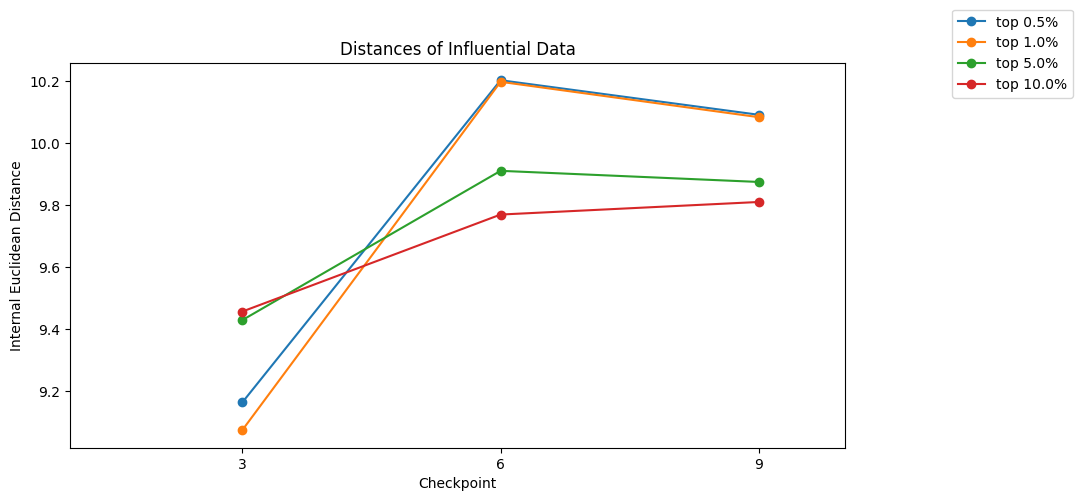

In [18]:
def calc_inter_dist(imgs):
    distances = euclidean_distances(imgs, imgs)
    mean_distance = np.mean(distances)
    return mean_distance

# Calculate distance of influential points towards other images
def calc_external_dist(inf_imgs, other_imgs):
    distances = euclidean_distances(inf_imgs, other_imgs)
    mean_distance = np.mean(distances)
    return mean_distance

# test selecting 0.5% 1% 5% 10% influential points
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))
plt.title("Distances of Influential Data")
for p in [0.005, 0.01, 0.05, 0.1]:
    mnist_ckpt_imgs = top_or_least_influences(mnist_influences, mnist_train, num_per_row=int(p*num_data))
    inter_distances = []
    for ckpt, ckpt_imgs in enumerate(mnist_ckpt_imgs):
        ckpt_imgs = np.array([img[0] for img in ckpt_imgs])
        # print(f"checkpoint: {ckpt}, shape:{ckpt_imgs.shape}")
        mean_dist = calc_inter_dist(ckpt_imgs)
        inter_distances.append(mean_dist)
    ax1.plot(checkpoint_labels, inter_distances, 'o-', label=f"top {p*100}%")
ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Internal Euclidean Distance")
ax1.set_xticks(checkpoint_labels)
fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

In [19]:
train_losses

[0.0033485949970781803,
 0.003460508771240711,
 0.0032124295830726624,
 0.0032650751527398825,
 0.0031798789277672768,
 0.0031907777301967144,
 0.0032488463912159204,
 0.003184145549312234,
 0.0031749927438795567,
 0.003389606485143304]

In [32]:
import sys
sys.path.append("/Users/nicolekan/Workspace/nus/data_valuation/src")

In [34]:
import pickle
import torch.nn as nn


class DigitNet(nn.Module):
    def __init__(self, input_dimensions=784, num_classes=10): 
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dimensions, 512),
            nn.ReLU(),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes),
            nn.Softmax(dim=-1)
            )
        
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.model(x)

results_dict = pickle.load(open("/Users/nicolekan/Workspace/nus/data_valuation/test.pkl", "rb"))

In [38]:
results_dict["model_eval_obj"]

ModelEvalObjects(model=DigitNet(
  (model): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=True)
    (5): Softmax(dim=-1)
  )
), checkpoint_filepaths=['/Users/nicolekan/Workspace/nus/data_valuation/checkpoint/DigitNet/epoch_3_0.3.pth', '/Users/nicolekan/Workspace/nus/data_valuation/checkpoint/DigitNet/epoch_6_0.6.pth', '/Users/nicolekan/Workspace/nus/data_valuation/checkpoint/DigitNet/epoch_9_0.9.pth'], train_losses=[array(0.0032872, dtype=float32), array(0.00331059, dtype=float32), array(0.00333463, dtype=float32), array(0.00327875, dtype=float32), array(0.00319951, dtype=float32), array(0.00330997, dtype=float32), array(0.00336287, dtype=float32), array(0.00315976, dtype=float32), array(0.00318125, dtype=float32), array(0.00319681, dtype=float32)], accuracies=[0.9108999967575073, 0.9247000217437744, 0.931999981

In [ ]:
results_dict[]